In [1]:
import sys
print("MLB 2026 Utility Defender Project")
print("Python version:", sys.version.split()[0])
print("Environment ready!")


MLB 2026 Utility Defender Project
Python version: 3.13.5
Environment ready!


In [2]:
%pip install pandas numpy matplotlib seaborn requests pybaseball


Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import pybaseball
print("All libraries imported successfully!")
print("Ready to collect 2026 MLB defensive data.")


All libraries imported successfully!
Ready to collect 2026 MLB defensive data.


In [4]:
# Connect to the MLB Stats API
url = "https://statsapi.mlb.com/api/v1/stats"
params = {
    "stats": "season",
    "group": "fielding",
    "sportIds": 1,
    "season": 2026,
    "playerPool": "ALL",
    "limit": 5000
}
response = requests.get(url, params=params, timeout=60)
print("Status code:", response.status_code)
print("Connection successful:", response.ok)
response.raise_for_status()
data = response.json()
print("Response sections:", list(data.keys()))


Status code: 200
Connection successful: True
Response sections: ['copyright', 'stats']


In [5]:
# Inspect the 2026 MLB fielding data
print("Number of stat groups:", len(data["stats"]))
for group in data["stats"]:
    print("Stat type:", group.get("type"))
    print("Number of records:", len(group.get("splits", [])))

    if group.get("splits"):
        first_record = group["splits"][0]

        print("\nFirst player record:")
        print("Player:", first_record.get("player"))
        print("Position:", first_record.get("position"))
        print("Available statistics:",
              list(first_record.get("stat", {}).keys()))


Number of stat groups: 1
Stat type: {'displayName': 'season'}
Number of records: 2748

First player record:
Player: {'id': 690953, 'fullName': 'Mick Abel', 'link': '/api/v1/people/690953', 'firstName': 'Mick', 'lastName': 'Abel', 'nameSlug': 'mick-abel-690953'}
Position: {'code': '1', 'name': 'Pitcher', 'type': 'Pitcher', 'abbreviation': 'P'}
Available statistics: ['age', 'gamesPlayed', 'gamesStarted', 'assists', 'putOuts', 'errors', 'chances', 'fielding', 'rangeFactorPerGame', 'rangeFactorPer9Inn', 'innings', 'games', 'doublePlays', 'triplePlays', 'throwingErrors']


In [6]:
# Check available positions and defensive innings
splits = data["stats"][0]["splits"]
positions = {}
for record in splits:
    position = record.get("position", {})
    code = position.get("code")
    name = position.get("name")

    positions[code] = name
print("Positions found:")
for code, name in sorted(positions.items()):
    print(code, "-", name)
print("\nInnings field available:",
      "innings" in splits[0]["stat"])
print("Example innings:",
      splits[0]["stat"].get("innings"))


Positions found:
1 - Pitcher
10 - Designated Hitter
2 - Catcher
3 - First Base
4 - Second Base
5 - Third Base
6 - Shortstop
7 - Outfielder
8 - Outfielder
9 - Outfielder

Innings field available: True
Example innings: 20.1


In [7]:
# Define the seven defensive positions
position_map = {
    "3": "1B",
    "4": "2B",
    "5": "3B",
    "6": "SS",
    "7": "LF",
    "8": "CF",
    "9": "RF"
}
records = []
for entry in splits:
    player = entry.get("player", {})
    position = entry.get("position", {})
    stats = entry.get("stat", {})
    code = str(position.get("code", ""))
    if code not in position_map:
        continue
    records.append({
        "player_id": player.get("id"),
        "player_name": player.get("fullName"),
        "position": position_map[code],
        "innings": stats.get("innings"),
        "games": stats.get("gamesPlayed")
    })
fielding_df = pd.DataFrame(records)
print("Total position records:", len(fielding_df))
print("Unique players:", fielding_df["player_id"].nunique())
display(fielding_df.head(10))


Total position records: 1326
Unique players: 583


,player_id,player_name,position,innings,games
0,682928,CJ Abrams,2B,103.0,14
1,682668,Luisangel Acuña,2B,1.0,1
2,682668,Luisangel Acuña,LF,3.0,1
3,666176,Jo Adell,LF,96.0,16
4,666176,Jo Adell,CF,10.0,3
5,682634,Kevin Alcántara,LF,21.0,6
6,682634,Kevin Alcántara,CF,6.0,3
7,682634,Kevin Alcántara,RF,10.0,2
8,677942,Blaze Alexander,SS,81.0,12
9,677942,Blaze Alexander,LF,42.0,8


In [8]:
# Convert baseball innings notation into outs
def innings_to_outs(innings):
    if pd.isna(innings):
        return 0

    parts = str(innings).split(".")
    whole_innings = int(parts[0])
    extra_outs = int(parts[1]) if len(parts) > 1 else 0

    if extra_outs not in (0, 1, 2):
        raise ValueError(f"Invalid innings: {innings}")

    return whole_innings * 3 + extra_outs

fielding_df["innings_outs"] = (
    fielding_df["innings"].apply(innings_to_outs)
)
fielding_df["innings_decimal"] = (
    fielding_df["innings_outs"] / 3
)
display(fielding_df.head(10))


,player_id,player_name,position,innings,games,innings_outs,innings_decimal
0,682928,CJ Abrams,2B,103.0,14,309,103.0
1,682668,Luisangel Acuña,2B,1.0,1,3,1.0
2,682668,Luisangel Acuña,LF,3.0,1,9,3.0
3,666176,Jo Adell,LF,96.0,16,288,96.0
4,666176,Jo Adell,CF,10.0,3,30,10.0
5,682634,Kevin Alcántara,LF,21.0,6,63,21.0
6,682634,Kevin Alcántara,CF,6.0,3,18,6.0
7,682634,Kevin Alcántara,RF,10.0,2,30,10.0
8,677942,Blaze Alexander,SS,81.0,12,243,81.0
9,677942,Blaze Alexander,LF,42.0,8,126,42.0


In [9]:
# Check for duplicate player-position records
duplicates = fielding_df.duplicated(
    subset=["player_id", "position"],
    keep=False
)
duplicate_records = fielding_df[duplicates]
print("Total records:", len(fielding_df))
print("Duplicate player-position records:",
      len(duplicate_records))
print("Unique player-position combinations:",
      fielding_df[
          ["player_id", "position"]
      ].drop_duplicates().shape[0])
display(duplicate_records.head(10))


Total records: 1326
Duplicate player-position records: 0
Unique player-position combinations: 1326


,player_id,player_name,position,innings,games,innings_outs,innings_decimal


In [10]:
# Calculate total defensive workload for each player
player_summary = (
    fielding_df.groupby(["player_id", "player_name"])
    .agg(
        total_outs=("innings_outs", "sum"),
        positions_played=("position", "nunique")
    )
    .reset_index()
)
# Convert total outs into decimal innings
player_summary["total_innings"] = (
    player_summary["total_outs"] / 3
)
# Sort by total defensive innings
player_summary = player_summary.sort_values(
    "total_innings",
    ascending=False
)
print("Total players:", len(player_summary))
display(player_summary.head(15))


Total players: 583


,player_id,player_name,total_outs,positions_played,total_innings
64,621566,Matt Olson,4275,2,1425.000000
446,691406,Junior Caminero,4208,2,1402.666667
390,683737,Michael Busch,4197,1,1399.000000
96,645277,Ozzie Albies,4179,1,1393.000000
529,702284,Cole Young,4171,2,1390.333333
135,663586,Austin Riley,4161,1,1387.000000
274,672695,Geraldo Perdomo,4116,1,1372.000000
134,663538,Nico Hoerner,4116,2,1372.000000
449,691718,Pete Crow-Armstrong,4110,1,1370.000000
520,701538,Jackson Merrill,4087,1,1362.333333


In [11]:
# Identify positions with meaningful playing time
MIN_POSITION_INNINGS = 100
qualified_positions = fielding_df[
    fielding_df["innings_decimal"] >= MIN_POSITION_INNINGS
].copy()
# Count qualifying positions per player
position_counts = (
    qualified_positions.groupby("player_id")
    .agg(
        qualifying_positions=("position", "nunique")
    )
    .reset_index()
)
# Combine with player summary
player_summary = player_summary.merge(
    position_counts,
    on="player_id",
    how="left"
)
player_summary["qualifying_positions"] = (
    player_summary["qualifying_positions"]
    .fillna(0)
    .astype(int)
)
# Players with at least two qualifying positions
multi_position_players = player_summary[
    player_summary["qualifying_positions"] >= 2
].copy()
print("Players with 100+ innings at 2+ positions:",
      len(multi_position_players))
display(
    multi_position_players[
        ["player_name", "total_innings",
         "positions_played", "qualifying_positions"]
    ].head(20)
)


Players with 100+ innings at 2+ positions: 137


,player_name,total_innings,positions_played,qualifying_positions
7,Nico Hoerner,1372.000000,2,2
13,Fernando Tatis Jr.,1343.000000,2,2
15,Brooks Lee,1339.666667,2,2
16,Carson Benge,1338.000000,3,2
18,Bo Bichette,1336.000000,3,2
21,Alec Bohm,1332.333333,2,2
22,Ernie Clement,1330.000000,4,2
23,Miguel Vargas,1329.666667,2,2
24,Mauricio Dubón,1325.000000,5,3
28,Bryson Stott,1321.000000,2,2


In [12]:
# Calculate secondary-position defensive innings
position_rankings = fielding_df.sort_values(
    ["player_id", "innings_outs"],
    ascending=[True, False]
).copy()
position_rankings["position_rank"] = (
    position_rankings.groupby("player_id").cumcount() + 1
)
# Extract each player's second-most-played position
secondary_positions = position_rankings[
    position_rankings["position_rank"] == 2
][["player_id", "position", "innings_decimal"]].copy()
secondary_positions = secondary_positions.rename(
    columns={
        "position": "secondary_position",
        "innings_decimal": "secondary_innings"
    }
)
# Merge with player summary
player_summary = player_summary.merge(
    secondary_positions,
    on="player_id",
    how="left"
)
player_summary["secondary_innings"] = (
    player_summary["secondary_innings"].fillna(0)
)
# Calculate percentage of innings at secondary position
player_summary["secondary_share"] = (
    player_summary["secondary_innings"]
    / player_summary["total_innings"]
)
display(
    player_summary[
        ["player_name", "total_innings",
         "secondary_position", "secondary_innings",
         "secondary_share"]
    ].head(20)
)


,player_name,total_innings,secondary_position,secondary_innings,secondary_share
0,Matt Olson,1425.000000,RF,1.000000,0.000702
1,Junior Caminero,1402.666667,1B,1.000000,0.000713
2,Michael Busch,1399.000000,NaN,0.000000,0.000000
3,Ozzie Albies,1393.000000,NaN,0.000000,0.000000
4,Cole Young,1390.333333,SS,40.000000,0.028770
5,Austin Riley,1387.000000,NaN,0.000000,0.000000
6,Geraldo Perdomo,1372.000000,NaN,0.000000,0.000000
7,Nico Hoerner,1372.000000,SS,352.333333,0.256803
8,Pete Crow-Armstrong,1370.000000,NaN,0.000000,0.000000
9,Jackson Merrill,1362.333333,NaN,0.000000,0.000000


In [13]:
# Apply utility defender eligibility criteria
MIN_TOTAL_INNINGS = 300
MIN_QUALIFYING_POSITIONS = 2
MIN_SECONDARY_SHARE = 0.20
eligible_players = player_summary[
    (player_summary["total_innings"] >= MIN_TOTAL_INNINGS)
    & (player_summary["qualifying_positions"] >= MIN_QUALIFYING_POSITIONS)
    & (player_summary["secondary_share"] >= MIN_SECONDARY_SHARE)
].copy()
eligible_players = eligible_players.sort_values(
    "total_innings",
    ascending=False
)
print("Total MLB players:", len(player_summary))
print("Eligible utility defenders:", len(eligible_players))
display(
    eligible_players[
        [
            "player_name",
            "total_innings",
            "qualifying_positions",
            "secondary_position",
            "secondary_innings",
            "secondary_share"
        ]
    ].head(20)
)


Total MLB players: 583
Eligible utility defenders: 107


,player_name,total_innings,qualifying_positions,secondary_position,secondary_innings,secondary_share
7,Nico Hoerner,1372.000000,2,SS,352.333333,0.256803
13,Fernando Tatis Jr.,1343.000000,2,2B,413.000000,0.307520
15,Brooks Lee,1339.666667,2,SS,400.000000,0.298582
18,Bo Bichette,1336.000000,2,SS,391.333333,0.292914
21,Alec Bohm,1332.333333,2,1B,424.666667,0.318739
24,Mauricio Dubón,1325.000000,3,SS,456.666667,0.344654
28,Bryson Stott,1321.000000,2,3B,367.666667,0.278325
29,Kevin McGonigle,1319.666667,2,3B,644.000000,0.488002
32,Sal Stewart,1311.666667,2,3B,306.666667,0.233799
38,Luke Keaschall,1298.666667,3,RF,451.666667,0.347793


In [14]:
# Examine positional workloads for eligible players
eligible_ids = eligible_players["player_id"]
eligible_fielding = fielding_df[
    fielding_df["player_id"].isin(eligible_ids)
].copy()
position_breakdown = eligible_fielding.pivot_table(
    index=["player_id", "player_name"],
    columns="position",
    values="innings_decimal",
    aggfunc="sum",
    fill_value=0
)
position_breakdown = position_breakdown.reset_index()
# Merge with eligible player totals
position_breakdown = eligible_players[
    ["player_id", "total_innings"]
].merge(
    position_breakdown,
    on="player_id",
    how="left"
)
print("Eligible players:", len(position_breakdown))
display(position_breakdown.head(15).round(1))


Eligible players: 107


,player_id,total_innings,player_name,1B,2B,3B,CF,LF,RF,SS
0,663538,1372.0,Nico Hoerner,0.0,1019.7,0.0,0.0,0.0,0.0,352.3
1,665487,1343.0,Fernando Tatis Jr.,0.0,413.0,0.0,0.0,0.0,930.0,0.0
2,686797,1339.7,Brooks Lee,0.0,0.0,939.7,0.0,0.0,0.0,400.0
3,666182,1336.0,Bo Bichette,0.0,1.0,943.7,0.0,0.0,0.0,391.3
4,664761,1332.3,Alec Bohm,424.7,0.0,907.7,0.0,0.0,0.0,0.0
5,643289,1325.0,Mauricio Dubón,0.0,34.0,46.0,125.0,663.3,0.0,456.7
6,681082,1321.0,Bryson Stott,0.0,953.3,367.7,0.0,0.0,0.0,0.0
7,805808,1319.7,Kevin McGonigle,0.0,0.0,644.0,0.0,0.0,0.0,675.7
8,701398,1311.7,Sal Stewart,948.0,57.0,306.7,0.0,0.0,0.0,0.0
9,807712,1298.7,Luke Keaschall,0.0,636.3,0.0,210.7,0.0,451.7,0.0


In [15]:
# Validate positional innings against total innings
position_columns = [
    "1B", "2B", "3B", "SS", "LF", "CF", "RF"
]
position_breakdown["calculated_total"] = (
    position_breakdown[position_columns].sum(axis=1)
)
position_breakdown["innings_difference"] = (
    position_breakdown["total_innings"]
    - position_breakdown["calculated_total"]
)
# Allow tiny floating-point rounding differences
validation_errors = position_breakdown[
    position_breakdown["innings_difference"].abs() > 0.01
]
print("Players checked:", len(position_breakdown))
print("Players with mismatched innings:", len(validation_errors))
display(
    position_breakdown[
        ["player_name", "total_innings",
         "calculated_total", "innings_difference"]
    ].head(15)
)

Players checked: 107
Players with mismatched innings: 0


,player_name,total_innings,calculated_total,innings_difference
0,Nico Hoerner,1372.000000,1372.000000,0.000000e+00
1,Fernando Tatis Jr.,1343.000000,1343.000000,0.000000e+00
2,Brooks Lee,1339.666667,1339.666667,2.273737e-13
3,Bo Bichette,1336.000000,1336.000000,0.000000e+00
4,Alec Bohm,1332.333333,1332.333333,0.000000e+00
5,Mauricio Dubón,1325.000000,1325.000000,0.000000e+00
6,Bryson Stott,1321.000000,1321.000000,0.000000e+00
7,Kevin McGonigle,1319.666667,1319.666667,2.273737e-13
8,Sal Stewart,1311.666667,1311.666667,0.000000e+00
9,Luke Keaschall,1298.666667,1298.666667,0.000000e+00


In [16]:
# Save Phase 1 datasets
from pathlib import Path
data_folder = Path.cwd().parent / "data"
data_folder.mkdir(parents=True, exist_ok=True)
fielding_df.to_csv(
    data_folder / "2026_position_fielding.csv",
    index=False
)
eligible_players.to_csv(
    data_folder / "2026_eligible_utility_players.csv",
    index=False
)
position_breakdown.to_csv(
    data_folder / "2026_position_breakdown.csv",
    index=False
)
print("Phase 1 datasets saved successfully!")
print("Location:", data_folder)
print("Files saved:", 3)


Phase 1 datasets saved successfully!
Location: /Users/cameronboardman/Desktop/MLB-2026-Utility-Defender-Value/data
Files saved: 3


In [17]:
# Test different secondary-position thresholds
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30]
results = []
for threshold in thresholds:
    qualifying = player_summary[
        (player_summary["total_innings"] >= 300)
        & (player_summary["qualifying_positions"] >= 2)
        & (player_summary["secondary_share"] >= threshold)
    ]
    results.append({
        "secondary_share_threshold": f"{threshold:.0%}",
        "eligible_players": len(qualifying)
    })
sensitivity_df = pd.DataFrame(results)
display(sensitivity_df)


,secondary_share_threshold,eligible_players
0,10%,129
1,15%,119
2,20%,107
3,25%,86
4,30%,57


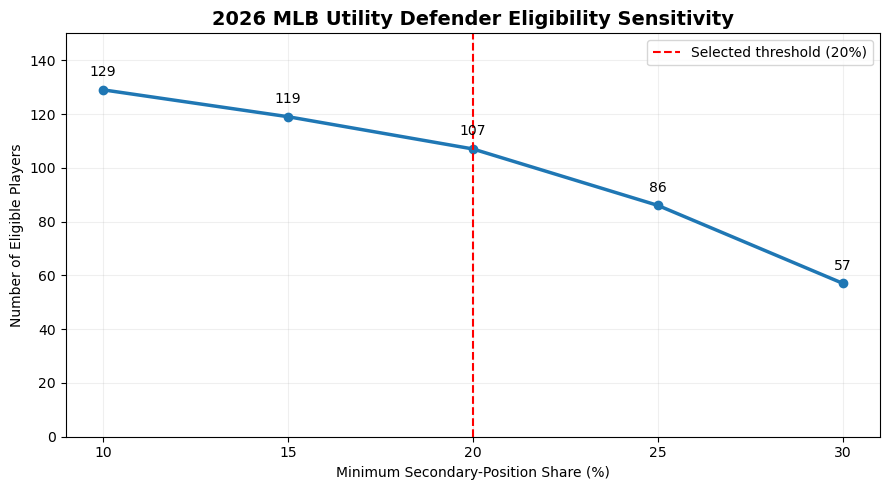

In [18]:
# Visualize eligibility threshold sensitivity
threshold_values = [10, 15, 20, 25, 30]
player_counts = sensitivity_df["eligible_players"]
plt.figure(figsize=(9, 5))
plt.plot(
    threshold_values,
    player_counts,
    marker="o",
    linewidth=2.5
)
plt.axvline(
    x=20,
    color="red",
    linestyle="--",
    label="Selected threshold (20%)"
)
for x, y in zip(threshold_values, player_counts):
    plt.annotate(
        str(y),
        (x, y),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center"
    )
plt.title(
    "2026 MLB Utility Defender Eligibility Sensitivity",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Minimum Secondary-Position Share (%)")
plt.ylabel("Number of Eligible Players")
plt.xticks(threshold_values)
plt.ylim(0, 150)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(
    "../visuals/eligibility_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [19]:
# Validate 2026 positional fielding data
print("Total position records:", len(fielding_df))
print("Unique players:", fielding_df["player_id"].nunique())
print("\nMissing values:")
print(fielding_df[
    ["player_id", "player_name", "position", "innings_outs"]
].isna().sum())
print("\nInvalid defensive innings:")
print("Negative outs:",
      (fielding_df["innings_outs"] < 0).sum())
print("Non-integer outs:",
      (fielding_df["innings_outs"] % 1 != 0).sum())
print("\nPosition distribution:")
print(fielding_df["position"].value_counts())
print("\nDuplicate player-position records:",
      fielding_df.duplicated(
          subset=["player_id", "position"]
      ).sum())


Total position records: 1326
Unique players: 583

Missing values:
player_id       0
player_name     0
position        0
innings_outs    0
dtype: int64

Invalid defensive innings:
Negative outs: 0
Non-integer outs: 0

Position distribution:
position
LF    265
RF    223
1B    179
3B    178
2B    174
CF    173
SS    134
Name: count, dtype: int64

Duplicate player-position records: 0


In [20]:
# Check MLB Stats API response completeness
group = data["stats"][0]
print("Returned records:", len(group["splits"]))
print("API totalSplits:", group.get("totalSplits"))
print("API limit:", group.get("limit"))
print("API offset:", group.get("offset"))
print("\nResponse metadata:")
print("Season:", group.get("season"))
print("Stat type:", group.get("type"))
print("\nFielding dataset records:", len(fielding_df))


Returned records: 2748
API totalSplits: 2748
API limit: None
API offset: None

Response metadata:
Season: None
Stat type: {'displayName': 'season'}

Fielding dataset records: 1326


## Phase 1: Data Collection and Player Eligibility
### Research Objective
Identify MLB players who demonstrated meaningful defensive versatility during the 2026 season.
### Data Source
MLB Stats API — 2026 regular-season fielding statistics.
### Eligible Positions
1B, 2B, 3B, SS, LF, CF, RF.
Pitchers, catchers, and designated hitters are excluded.
### Eligibility Criteria
Players must satisfy all three requirements:
1. At least 300 total defensive innings.
2. At least 100 defensive innings at two different positions.
3. At least 20% of defensive innings at their second-most-played position.
These are research-defined thresholds rather than official MLB classifications.
### Data Processing
- Retrieved 2,748 fielding records.
- Retained 1,326 records across seven positions.
- Identified 583 unique players.
- Converted baseball innings notation into defensive outs.
- Verified positional workload calculations.
- Checked for missing values, invalid innings, and duplicates.
### Sensitivity Analysis
Changing the secondary-position share threshold produced:
- 10%: 129 players
- 15%: 119 players
- 20%: 107 players
- 25%: 86 players
- 30%: 57 players
The 20% threshold was selected as a preliminary balance between meaningful positional versatility and sample size.
### Phase 1 Results
107 players qualified under the preliminary eligibility criteria.
### Limitations
Eligibility measures positional workload, not defensive ability.
The MLB API response matched its reported record count, but independent verification against another source remains necessary.
Advanced defensive metrics will be incorporated in Phase 2.
